<a href="https://colab.research.google.com/github/fiannnn9090/prediksi-rumah-depok/blob/main/Early_Bird_Prediksi_Harga_Rumah.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Early Bird Bengkel Koding Data Science: Prediksi Harga Rumah Depok

**Nama:** Aliffian Alham Maesanjaya &nbsp;|&nbsp; **NIM:** A11.2022.14514

**Tujuan:** memprediksi harga listing rumah (regresi) di Depok dan sekitarnya dari data hasil scraping (~40.000 baris), melewati siklus lengkap: EDA, direct modeling, preprocessing, feature selection, hyperparameter tuning, dan deployment.

**Link:** [GitHub](https://github.com/fiannnn9090/prediksi-rumah-depok) | [Aplikasi Streamlit](https://prediksi-rumah-depok.streamlit.app/)

**Alur notebook:** 1) EDA, 2) Direct modeling (kontrol), 3) Cleaning + modeling ulang, 4) Feature selection, 5) Hyperparameter tuning + evaluasi, 6) Penyimpanan model untuk deployment.

In [1]:
import os, re, json, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
N_ITER = 15   # jumlah kandidat pada RandomizedSearchCV

if not os.path.exists("Raw-Final-Rumah.csv"):
    from google.colab import files
    files.upload()          # upload Raw-Final-Rumah.csv

Saving Raw-Final-Rumah.csv to Raw-Final-Rumah.csv


## 1. Eksplorasi Data (EDA)

### 1.1 Karakteristik dan kualitas data mentah
Hampir semua kolom bertipe teks bersatuan (mis. "2,5 Miliar", "LT : 438 m²"). Kita periksa pola isi tiap kolom (angka diganti `9`) untuk menemukan variasi format dan isi yang tidak sesuai nama kolom.

In [2]:
df = pd.read_csv("Raw-Final-Rumah.csv")
print(df.shape)
display(df.head(10))
print(df.isna().sum())
print("Duplikat identik:", df.duplicated().sum())
print("Duplikat tanpa Page:", df.drop(columns="Page").duplicated().sum())
print("Duplikat tanpa Page & Kecamatan:", df.drop(columns=["Page","Kecamatan"]).duplicated().sum())

def pola(s):
    return "NaN" if pd.isna(s) else re.sub(r"\d+", "9", str(s))
for c in ["Harga","Kamar Tidur","Kamar Mandi","Garasi","Luas Tanah","Luas Bangunan"]:
    print("=====", c); print(df[c].map(pola).value_counts().head(20))
print(df["Kecamatan"].value_counts())

(40200, 8)


,Harga,Kamar Tidur,Kamar Mandi,Garasi,Luas Tanah,Luas Bangunan,Kecamatan,Page
0,"2,5 Miliar",4,3,10,LT : 438 m²,LB : 110 m²,Tapos,129
1,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Pancoran Mas,129
2,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Cipayung,129
3,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Rangkapanjaya,129
4,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Pancoran Mas,129
5,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Cipayung,129
6,950 Juta,2,1,1,LT : 87 m²,LB : 50 m²,Sawangan,129
7,525 Juta,2,1,LB:41 m²,NaN,NaN,Cinere,129
8,"2,5 Miliar",3,2,LT:409 m²,LB : 300 m²,NaN,Sukmajaya,129
9,"3,7 Miliar",4,3,LT:280 m²,LB : 240 m²,NaN,Cinere,129


Harga                0
Kamar Tidur          9
Kamar Mandi       4403
Garasi            5189
Luas Tanah        7699
Luas Bangunan    15602
Kecamatan            0
Page                 0
dtype: int64
Duplikat identik: 1525
Duplikat tanpa Page: 9478
Duplikat tanpa Page & Kecamatan: 12331
===== Harga
Harga
9,9 Miliar           17462
9 Juta               13793
9,9 Miliar Total      3731
9 Miliar              2800
9 Miliar Total        1352
9 Juta Total           683
9,9 Juta Total         124
9,9 Juta                79
9,9 Triliun Total       51
Hubungi Agen            41
9 Juta /m²              22
9,9 Juta /m²            22
9 Ribu                  11
9,9 Miliar /m²           9
9 Triliun Total          8
9,9 Triliun              7
9 Miliar /m²             2
9,9 Ribu                 1
9 Ribu Total             1
9,9 Juta /ha             1
Name: count, dtype: int64
===== Kamar Tidur
Kamar Tidur
9          35250
LT:9 m²     4851
LB:9 m²       90
NaN            9
Name: count, dtype: int64
===== K

**Temuan dari pola isi kolom:**
- **Harga** punya banyak variasi: satuan Triliun/Miliar/Juta/Ribu, akhiran "Total", harga per `/m²` dan `/ha`, serta "Hubungi Agen" (tanpa harga).
- **Kolom bergeser ke kiri.** Isi `Kamar Tidur`, `Kamar Mandi`, dan `Garasi` sering berupa "LT: … m²" atau "LB: … m²". Ini terjadi karena scraper mengambil atribut secara berurutan: bila satu atribut (misalnya garasi) tidak ada, atribut sesudahnya maju ke kolom sebelumnya. Tidak ada baris yang punya celah di tengah, sehingga isi bisa dipulihkan dengan mengenali awalan teksnya (`LT`, `LB`, atau angka polos).
- **Duplikat tersembunyi:** listing yang sama dicatat dengan kecamatan atau halaman berbeda.
- `Page` hanyalah nomor halaman scraping (0 sampai 2009, tepat 20 baris per halaman), bukan karakteristik rumah.
- `Kecamatan` bercampur level wilayah (kecamatan, kelurahan, kompleks perumahan) dan sangat timpang (Cinere 8.602 baris, Sumur Batu 1 baris).

### 1.2 Parsing ulang ke angka
- **Harga:** angka dan satuan dipisah, jenis harga (Total, /m², /ha) dicatat.
- **Fitur rumah:** semua isi lima kolom dikumpulkan lalu dikenali dari awalan teks: `LT` menjadi luas tanah, `LB` menjadi luas bangunan, angka polos berurutan menjadi kamar tidur, kamar mandi, garasi. *Asumsi:* bila hanya ada dua angka polos, garasi dianggap kosong (garasi paling sering tidak diisi).

In [3]:
C = ["Kamar Tidur","Kamar Mandi","Garasi","Luas Tanah","Luas Bangunan"]

def parse_harga(s):
    m = re.match(r"^([\d.,]+)\s*(Triliun|Miliar|Juta|Ribu)\s*(Total|/m²|/ha)?$", str(s).strip())
    if not m: return pd.Series([np.nan, "tanpa_harga"])
    angka = float(m.group(1).replace(",", "."))
    angka *= {"Triliun":1e12,"Miliar":1e9,"Juta":1e6,"Ribu":1e3}[m.group(2)]
    return pd.Series([angka, m.group(3) or "Total"])
df[["harga","jenis_harga"]] = df["Harga"].apply(parse_harga)

def parse_fitur(r):
    lt = lb = np.nan; angka = []
    for v in r[C]:
        if pd.isna(v): continue
        v = str(v); n = float(re.sub(r"[^\d]", "", v))
        if v.startswith("LT"): lt = n
        elif v.startswith("LB"): lb = n
        else: angka.append(n)
    kt, km, gr = (angka + [np.nan]*3)[:3]
    return pd.Series([kt, km, gr, lt, lb])
df[["kt","km","garasi","lt","lb"]] = df.apply(parse_fitur, axis=1)

### 1.3 Tabel temuan kualitas data

In [4]:
tabel = pd.DataFrame([
    ["Kolom bergeser (isi tidak sesuai nama)", int(df[C[:3]].apply(lambda c: c.astype(str).str.startswith(("LT","LB"))).any(axis=1).sum()), "Atribut kosong membuat nilai berikutnya maju ke kiri"],
    ["Duplikat identik", df.duplicated().sum(), "Listing tampil ulang"],
    ["Duplikat tanpa Page & Kecamatan", df.drop(columns=["Page","Kecamatan"]).duplicated().sum(), "Listing sama dicatat di banyak kecamatan/halaman"],
    ["Harga 'Hubungi Agen'", (df.jenis_harga=="tanpa_harga").sum(), "Harga tidak dipublikasikan"],
    ["Harga per m² / per ha", df.jenis_harga.isin(["/m²","/ha"]).sum(), "Bukan harga total"],
    ["Harga < Rp100 juta", (df.harga<1e8).sum(), "Salah input (satuan Ribu) / bukan rumah"],
    ["Harga > Rp100 miliar", (df.harga>1e11).sum(), "Salah input (satuan Triliun)"],
    ["Missing Luas Bangunan", df.lb.isna().sum(), "Atribut tidak ada di listing"],
    ["Missing Garasi", df.garasi.isna().sum(), "Atribut tidak ada di listing"],
    ["Kamar Tidur ≥ 10", (df.kt>=10).sum(), "Kos/asrama atau salah input"],
    ["Luas Tanah > 5.000 m²", (df["lt"]>5000).sum(), "Lahan/komersial atau salah input"],
], columns=["Masalah","Jumlah baris","Kemungkinan penyebab"])
display(tabel)

,Masalah,Jumlah baris,Kemungkinan penyebab
0,Kolom bergeser (isi tidak sesuai nama),15579,Atribut kosong membuat nilai berikutnya maju k...
1,Duplikat identik,1525,Listing tampil ulang
2,Duplikat tanpa Page & Kecamatan,12331,Listing sama dicatat di banyak kecamatan/halaman
3,Harga 'Hubungi Agen',41,Harga tidak dipublikasikan
4,Harga per m² / per ha,56,Bukan harga total
5,Harga < Rp100 juta,486,Salah input (satuan Ribu) / bukan rumah
6,Harga > Rp100 miliar,275,Salah input (satuan Triliun)
7,Missing Luas Bangunan,4331,Atribut tidak ada di listing
8,Missing Garasi,15593,Atribut tidak ada di listing
9,Kamar Tidur ≥ 10,765,Kos/asrama atau salah input


### 1.4 Visualisasi
Untuk EDA dipakai data kerja: harga total yang wajar (Rp100 juta sampai Rp100 miliar) tanpa duplikat listing.

Data kerja EDA: 27157
Skewness harga: 6.59 | setelah log: 0.59


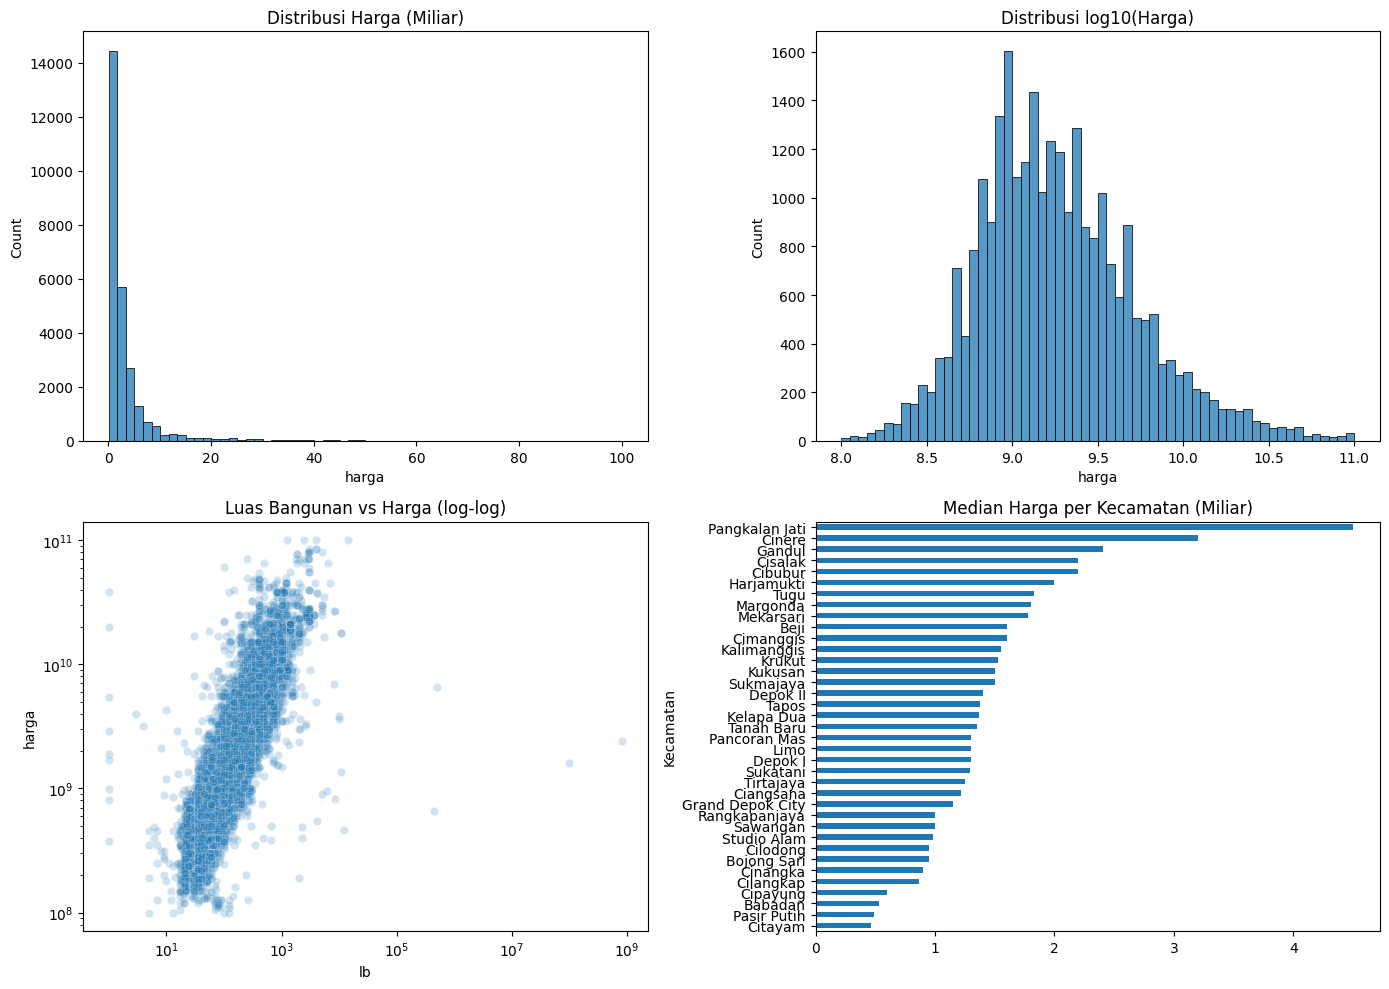

harga     1.000
kt        0.676
km        0.733
garasi    0.469
lt        0.838
lb        0.883
Name: harga, dtype: float64
count    2.466100e+04
mean     1.800970e+07
std      2.770761e+08
min      3.000000e+00
25%      1.011458e+07
50%      1.311538e+07
75%      1.718750e+07
max      3.800000e+10
Name: harga_per_m2_lb, dtype: float64


In [5]:
d = df[(df.jenis_harga=="Total") & df.harga.between(1e8, 1e11)]
d = d.drop_duplicates(["harga","kt","km","garasi","lt","lb"]).copy()
d["harga_per_m2_lb"] = d.harga / d.lb
print("Data kerja EDA:", len(d))
print("Skewness harga:", round(d.harga.skew(),2), "| setelah log:", round(np.log1p(d.harga).skew(),2))

fig, ax = plt.subplots(2, 2, figsize=(14,10))
sns.histplot(d.harga/1e9, bins=60, ax=ax[0,0]); ax[0,0].set_title("Distribusi Harga (Miliar)")
sns.histplot(np.log10(d.harga), bins=60, ax=ax[0,1]); ax[0,1].set_title("Distribusi log10(Harga)")
sns.scatterplot(x=d.lb, y=d.harga, alpha=.2, ax=ax[1,0]); ax[1,0].set(xscale="log", yscale="log", title="Luas Bangunan vs Harga (log-log)")
med = d.groupby("Kecamatan").harga.median().sort_values()/1e9
med.plot.barh(ax=ax[1,1], title="Median Harga per Kecamatan (Miliar)"); plt.tight_layout(); plt.show()

print(d[["harga","kt","km","garasi","lt","lb"]].corr(method="spearman")["harga"].round(3))
print(d.harga_per_m2_lb.describe().round(0))

### 1.5 Insight utama dan keputusan tahap berikutnya

**Insight 1: Harga sangat miring ke kanan.** Skewness sekitar 6,6 pada harga mentah, turun menjadi sekitar 0,6 setelah transformasi log. Sedikit listing mewah menarik rata-rata ke atas dan membuat error model didominasi listing mahal. **Keputusan:** model dilatih pada `log(Harga)` dan prediksi dikembalikan ke Rupiah saat evaluasi; MAPE dilaporkan selain MAE agar error relatif terlihat.

**Insight 2: Luas adalah penentu harga terkuat.** Korelasi Spearman dengan harga: luas bangunan 0,88, luas tanah 0,84, kamar mandi 0,73, kamar tidur 0,68, garasi 0,47. Hubungan luas dan harga tidak linear (terlihat pada plot log-log), dan luas bangunan kosong di banyak baris. **Keputusan:** luas diberi transformasi log, baris dengan luas kosong tidak dibuang melainkan diimputasi (median, di dalam pipeline) dengan indikator missing, dan dipilih model berbasis pohon/ensemble yang menangkap hubungan non-linear.

**Insight 3: Lokasi menentukan level harga, tetapi datanya timpang.** Median harga Pangkalan Jati sekitar Rp4,5 miliar, sekitar 10 kali Citayam (sekitar Rp0,46 miliar), sementara jumlah data per kecamatan sangat tidak merata (Cinere 8.602 baris, Sumur Batu 1 baris). **Keputusan:** kecamatan dengan data sangat sedikit digabung menjadi "Lainnya" dan lokasi di-encode dengan *target encoding* (bukan one-hot penuh dari puluhan kategori) agar tidak overfit.

**Insight 4: Banyak harga ekstrem adalah salah input, bukan rumah mahal.** Harga per m² bangunan memiliki median sekitar Rp13 juta, tetapi maksimumnya mencapai Rp38 miliar per m²; ada pula harga berskala Triliun dan Ribu. **Keputusan:** outlier dibuang dengan aturan harga per m² yang wajar (bukan sekadar memotong harga mentah), sehingga rumah mewah yang valid tetap tersimpan.

## 2. Direct Modeling (kontrol, sebelum preprocessing)

Enam model dibangun langsung pada data mentah dengan konversi **minimal** agar bisa dijalankan: harga di-parse apa adanya, hanya angka yang diambil dari tiap kolom (kolom bergeser tidak diperbaiki), missing diisi median, Kecamatan di-label-encode, `Page` ikut dipakai, tanpa dedup, tanpa penanganan outlier, tanpa log. Baris "Hubungi Agen" tidak bisa dilatih karena targetnya tidak ada.

**Alasan pemilihan model:**

| Model | Alasan |
|---|---|
| Linear Regression | Baseline paling sederhana; menguji apakah hubungan fitur dan harga cukup linear |
| KNN | Berbasis kemiripan: rumah dengan spesifikasi mirip berharga mirip; peka terhadap skala dan outlier sehingga menunjukkan dampak data kotor |
| Decision Tree | Menangkap hubungan non-linear dan interaksi (luas × lokasi) tanpa normalisasi |
| Random Forest (ensemble bagging) | Merata-ratakan banyak pohon, lebih stabil terhadap noise dan outlier dibanding satu pohon |
| HistGradientBoosting (ensemble boosting) | Boosting cepat untuk data puluhan ribu baris, menangani missing value secara bawaan |
| XGBoost (ensemble boosting) | Standar kuat untuk data tabular, dilengkapi regularisasi |

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler, TargetEncoder
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score

raw = pd.read_csv("Raw-Final-Rumah.csv")
S = {"Triliun":1e12,"Miliar":1e9,"Juta":1e6,"Ribu":1e3}
def naif_harga(s):
    m = re.match(r"([\d.,]+)\s*(Triliun|Miliar|Juta|Ribu)", str(s))
    return float(m.group(1).replace(",", ".")) * S[m.group(2)] if m else np.nan
raw["y"] = raw["Harga"].apply(naif_harga)
raw = raw.dropna(subset=["y"])

Xr = pd.DataFrame({c: raw[c].astype(str).str.replace(r"[^\d]", "", regex=True)
                          .replace("", np.nan).astype(float) for c in C})
Xr["Kecamatan"] = raw["Kecamatan"].astype("category").cat.codes
Xr["Page"] = raw["Page"]
Xr = Xr.fillna(Xr.median())
yr = raw["y"]
Xtr0, Xte0, ytr0, yte0 = train_test_split(Xr, yr, test_size=0.2, random_state=42)

models0 = {
  "Linear Regression": LinearRegression(),
  "KNN": make_pipeline(StandardScaler(), KNeighborsRegressor(5)),
  "Decision Tree": DecisionTreeRegressor(random_state=42),
  "Random Forest": RandomForestRegressor(100, n_jobs=-1, random_state=42),
  "HistGradientBoosting": HistGradientBoostingRegressor(random_state=42),
  "XGBoost": XGBRegressor(n_estimators=200, random_state=42, n_jobs=-1),
}
rows = []
for n, m in models0.items():
    t = time.time(); m.fit(Xtr0, ytr0); p = m.predict(Xte0)
    rows.append([n, mean_absolute_error(yte0,p), mean_absolute_percentage_error(yte0,p), r2_score(yte0,p), round(time.time()-t,1)])
hasil_direct = pd.DataFrame(rows, columns=["Model","MAE","MAPE","R2","detik"])
pd.set_option("display.float_format", "{:,.3f}".format)
display(hasil_direct)

,Model,MAE,MAPE,R2,detik
0,Linear Regression,"2,361,873,573,870.843","1,991.913",-779.639,0.000
1,KNN,"165,353,439,185.881",118.349,0.135,0.300
2,Decision Tree,"313,133,211,790.961",36.851,-8.547,0.300
3,Random Forest,"337,528,319,645.608",277.237,-0.783,11.800
4,HistGradientBoosting,"298,053,786,558.407","1,678.932",-0.124,0.100
5,XGBoost,"386,463,085,301.346","1,059.707",-7.762,0.400


**Interpretasi:** median harga sebenarnya Rp1,5 miliar, tetapi MAE model mencapai ratusan miliar sampai triliunan Rupiah dan R² negatif pada sebagian besar model (lebih buruk daripada menebak rata-rata). Penyebabnya, target mengandung nilai ekstrem akibat salah input satuan (misalnya Rp1,9 kuadriliun) yang merusak model, terutama Linear Regression. Ini menjadi bukti kuantitatif untuk Insight 1 dan 4 bahwa pembersihan data wajib dilakukan.

## 3. Cleaning, Preprocessing, dan Modeling Ulang

### 3.1 Aturan cleaning (deterministik, sebelum split)
Setiap aturan dicatat jumlah baris yang dibuang agar keputusan dapat dipertanggungjawabkan.

- **Harga bukan total / tanpa harga:** harga per m², per ha, dan "Hubungi Agen" dibuang (jumlahnya kecil dan bukan harga total).
- **Duplikat listing:** diidentifikasi dari kombinasi harga dan seluruh spesifikasi, **mengabaikan `Page` dan `Kecamatan`**, karena listing yang sama tampil di banyak halaman dan kecamatan. Risikonya, dua rumah berbeda dengan spesifikasi dan harga identik (unit kembar satu perumahan) ikut terbuang; risiko ini diterima karena duplikat nyata jauh lebih banyak dan duplikat dapat menyebabkan *data leakage* ke data uji.
- **Outlier:** harga di luar Rp150 juta sampai Rp50 miliar, kamar tidur/mandi lebih dari 10 atau garasi lebih dari 6, luas di luar batas wajar, luas bangunan lebih dari 3 kali luas tanah, serta harga per m² tanah di luar Rp1 sampai 100 juta dan per m² bangunan di luar Rp1,5 sampai 100 juta. Aturan berbasis harga per m² dipilih agar rumah mewah yang valid tidak ikut terpotong.
- **`Page` dibuang** (nomor halaman scraping). **Kecamatan** dengan data kurang dari 100 baris digabung menjadi "Lainnya".
- *Keterbatasan:* kolom Kecamatan bercampur level wilayah (kecamatan/kelurahan/kompleks). Pemetaan ke satu level membutuhkan referensi wilayah eksternal sehingga tidak dilakukan.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

d = df.copy(); log = [("awal", len(d))]
def drop(mask, nama):
    global d; n = int(mask.sum()); d = d[~mask]; log.append((nama, n))

drop(d.jenis_harga != "Total", "harga bukan total / tanpa harga")
drop(d.duplicated(["harga","kt","km","garasi","lt","lb"]), "duplikat listing (abaikan Page & Kecamatan)")
drop(d["lt"].isna() & d["lb"].isna(), "tanpa luas tanah & bangunan")
drop(~d.harga.between(1.5e8, 5e10), "harga di luar Rp150 jt - Rp50 M")
drop((d.kt>10)|(d.km>10)|(d.garasi>6), "kamar/garasi tidak wajar")
drop((d["lt"]>10000)|(d.lb>3000)|(d["lt"]<15)|(d.lb<15), "luas tidak wajar")
drop(d.lb > 3*d["lt"], "LB > 3x LT")
hpt, hpb = d.harga/d["lt"], d.harga/d.lb
drop((hpt<1e6)|(hpt>1e8)|(hpb<1.5e6)|(hpb>1e8), "harga/m² tidak wajar")
display(pd.DataFrame(log, columns=["Langkah","Baris dibuang"]))

cnt = d.Kecamatan.value_counts()
d["kec"] = np.where(d.Kecamatan.isin(cnt[cnt<100].index), "Lainnya", d.Kecamatan)

# Feature engineering
d["log_lt"] = np.log1p(d["lt"]); d["log_lb"] = np.log1p(d.lb); d["lb_per_lt"] = d.lb/d["lt"]
num = ["kt","km","garasi","log_lt","log_lb","lb_per_lt"]
X = d[num+["kec"]]; y = np.log1p(d.harga)
print("Data bersih:", len(d), "| kecamatan:", d.kec.nunique())

,Langkah,Baris dibuang
0,awal,40200
1,harga bukan total / tanpa harga,97
2,duplikat listing (abaikan Page & Kecamatan),12350
3,tanpa luas tanah & bangunan,18
4,harga di luar Rp150 jt - Rp50 M,793
5,kamar/garasi tidak wajar,589
6,luas tidak wajar,123
7,LB > 3x LT,89
8,harga/m² tidak wajar,85


Data bersih: 26056 | kecamatan: 29


### 3.2 Feature engineering dan pipeline
- Luas tanah dan bangunan di-log (Insight 2) serta ditambah rasio bangunan/tanah (`lb_per_lt`). Ini juga menstabilkan Linear Regression yang tanpa log gagal total.
- **Imputasi median (dengan indikator missing) dan target encoding Kecamatan berada di dalam pipeline**, sehingga hanya "belajar" dari data latih (mencegah leakage).
- Target di-log, dan evaluasi dilakukan setelah dikembalikan ke Rupiah.
- Model yang digunakan sama dengan direct modeling.

In [8]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)

def prep2(cols, scale=False):
    n = [("imp", SimpleImputer(strategy="median", add_indicator=True))]
    if scale: n.append(("sc", StandardScaler()))
    return ColumnTransformer([("num", Pipeline(n), cols), ("kec", TargetEncoder(random_state=42), ["kec"])])

M = {"Linear Regression": (LinearRegression(), True),
     "KNN": (KNeighborsRegressor(5), True),
     "Decision Tree": (DecisionTreeRegressor(random_state=42), False),
     "Random Forest": (RandomForestRegressor(100, n_jobs=-1, random_state=42), False),
     "HistGradientBoosting": (HistGradientBoostingRegressor(random_state=42), False),
     "XGBoost": (XGBRegressor(n_estimators=200, random_state=42, n_jobs=-1), False)}
MAE, MAPE = mean_absolute_error, mean_absolute_percentage_error

def evaluasi(cols):
    rows = []
    for n, (m, sc) in M.items():
        p = make_pipeline(prep2(cols, sc), m).fit(Xtr[cols+["kec"]], ytr)
        pr, a = np.expm1(p.predict(Xte[cols+["kec"]])), np.expm1(yte)
        rows.append([n, MAE(a,pr), MAPE(a,pr), r2_score(a,pr)])
    return pd.DataFrame(rows, columns=["Model","MAE","MAPE","R2"])

hasil_clean = evaluasi(num); display(hasil_clean)

,Model,MAE,MAPE,R2
0,Linear Regression,"1,028,879,316.870",0.316,0.693
1,KNN,"1,049,692,375.378",0.309,0.678
2,Decision Tree,"1,022,644,924.133",0.341,0.649
3,Random Forest,"821,365,834.482",0.256,0.766
4,HistGradientBoosting,"938,441,060.304",0.277,0.726
5,XGBoost,"897,814,016.500",0.268,0.741


**Interpretasi:** setelah preprocessing, MAE turun dari ratusan miliar/triliunan Rupiah menjadi sekitar Rp0,8 sampai 1,0 miliar, MAPE dari ratusan/ribuan persen menjadi sekitar 25 sampai 34%, dan R² dari negatif menjadi 0,65 sampai 0,77. Random Forest terbaik.

*Catatan kejujuran:* perbandingan ini tidak sepenuhnya apple-to-apple karena baseline diuji pada test set mentah (penuh outlier) sedangkan model bersih diuji pada test set bersih (sesuai ketentuan soal). Sebagian besar lonjakan skor memang berasal dari data yang lebih bersih.

## 4. Feature Selection

Tiga sudut pandang digabung: korelasi Spearman (hubungan monoton), *mutual information* (hubungan non-linear), dan *permutation importance* dari Random Forest. Keputusan akhir diverifikasi dengan cross-validation pada data latih.

In [9]:
from scipy.stats import spearmanr
from sklearn.feature_selection import mutual_info_regression
from sklearn.model_selection import cross_val_score, RandomizedSearchCV
from sklearn.inspection import permutation_importance

Xn = Xtr[num].fillna(Xtr[num].median())
tab = pd.DataFrame({"spearman": {c: abs(spearmanr(Xn[c], ytr)[0]) for c in num},
                    "mutual_info": dict(zip(num, mutual_info_regression(Xn, ytr, random_state=42)))})
rf = make_pipeline(prep2(num), RandomForestRegressor(100, n_jobs=-1, random_state=42)).fit(Xtr, ytr)
pi = permutation_importance(rf, Xtr, ytr, n_repeats=3, random_state=42, n_jobs=-1)
tab["perm_importance"] = pd.Series(dict(zip(num+["kec"], pi.importances_mean)))
display(tab.round(4))

def cv_r2(cols):
    p = make_pipeline(prep2(cols), RandomForestRegressor(100, n_jobs=-1, random_state=42))
    return cross_val_score(p, Xtr[cols+["kec"]], ytr, cv=3, scoring="r2").mean()
print("CV R2 semua fitur  :", round(cv_r2(num), 4))
print("CV R2 tanpa garasi :", round(cv_r2([c for c in num if c != "garasi"]), 4))

sel = [c for c in num if c != "garasi"]
hasil_sel = evaluasi(sel); display(hasil_sel)

,spearman,mutual_info,perm_importance
kt,0.601,0.281,0.014
km,0.600,0.318,0.050
garasi,0.238,0.069,0.011
log_lt,0.811,0.873,1.030
log_lb,0.818,0.885,0.392
lb_per_lt,0.065,0.338,0.040


CV R2 semua fitur  : 0.877
CV R2 tanpa garasi : 0.8764


,Model,MAE,MAPE,R2
0,Linear Regression,"1,029,390,734.822",0.316,0.692
1,KNN,"998,158,762.120",0.297,0.701
2,Decision Tree,"1,019,544,848.951",0.334,0.626
3,Random Forest,"814,462,041.455",0.257,0.770
4,HistGradientBoosting,"938,912,258.568",0.278,0.726
5,XGBoost,"909,250,702.566",0.273,0.737


**Keputusan:** `garasi` dibuang. Fitur ini paling lemah di ketiga metode (Spearman 0,24; mutual information 0,07; permutation importance 0,01), dan membuangnya hanya menurunkan R² validasi dari 0,8770 menjadi 0,8764 (selisih diabaikan). Menghapus Kecamatan, sebaliknya, menurunkan R² validasi jauh (sekitar 0,85), sehingga lokasi dipertahankan. `lb_per_lt` korelasi linearnya kecil tetapi mutual information-nya tinggi, artinya hubungannya non-linear dan dimanfaatkan model pohon. Fitur akhir: `kt`, `km`, `log_lt`, `log_lb`, `lb_per_lt`, dan `kec`.

## 5. Hyperparameter Tuning dan Evaluasi Akhir

Tiga model ensemble terbaik (Random Forest, HistGradientBoosting, XGBoost) dituning dengan `RandomizedSearchCV` (CV 3-fold) **hanya pada data latih**, dengan metrik MAE. Test set baru dipakai untuk evaluasi akhir.

In [10]:
grids = {
 "Random Forest": (RandomForestRegressor(random_state=42, n_jobs=-1),
    {"n_estimators":[100,200,300],"max_depth":[None,20,30],"min_samples_leaf":[1,2,3,5],"max_features":[0.5,0.7,1.0]}),
 "HistGradientBoosting": (HistGradientBoostingRegressor(random_state=42),
    {"learning_rate":[0.03,0.05,0.1],"max_iter":[200,400],"max_leaf_nodes":[15,31,63],"min_samples_leaf":[10,20,40]}),
 "XGBoost": (XGBRegressor(random_state=42, n_jobs=-1),
    {"n_estimators":[200,400],"max_depth":[4,6,8],"learning_rate":[0.03,0.05,0.1],"subsample":[0.7,0.9,1.0],"colsample_bytree":[0.7,1.0]}),
}
rows, best = [], {}
for n, (m, g) in grids.items():
    pipe = Pipeline([("prep", prep2(sel)), ("model", m)])
    s = RandomizedSearchCV(pipe, {"model__"+k: v for k, v in g.items()}, n_iter=N_ITER, cv=3,
                           scoring="neg_mean_absolute_error", random_state=42, n_jobs=-1).fit(Xtr[sel+["kec"]], ytr)
    pr, a = np.expm1(s.predict(Xte[sel+["kec"]])), np.expm1(yte)
    rows.append([n, MAE(a,pr), MAPE(a,pr), r2_score(a,pr)]); best[n] = s
    print(n, s.best_params_)
hasil_tuned = pd.DataFrame(rows, columns=["Model","MAE","MAPE","R2"]); display(hasil_tuned)

final = pd.concat([hasil_clean.assign(Tahap="3. Preprocessing"),
                   hasil_sel.assign(Tahap="4. Feature selection"),
                   hasil_tuned.assign(Tahap="5. Tuning")]).sort_values("MAE")
display(final.reset_index(drop=True))

Random Forest {'model__n_estimators': 300, 'model__min_samples_leaf': 2, 'model__max_features': 0.5, 'model__max_depth': 30}
HistGradientBoosting {'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 63, 'model__max_iter': 400, 'model__learning_rate': 0.1}
XGBoost {'model__subsample': 0.7, 'model__n_estimators': 200, 'model__max_depth': 8, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.7}


,Model,MAE,MAPE,R2
0,Random Forest,"835,219,282.050",0.254,0.759
1,HistGradientBoosting,"914,369,693.438",0.271,0.727
2,XGBoost,"892,386,787.257",0.267,0.748


,Model,MAE,MAPE,R2,Tahap
0,Random Forest,"814,462,041.455",0.257,0.770,4. Feature selection
1,Random Forest,"821,365,834.482",0.256,0.766,3. Preprocessing
2,Random Forest,"835,219,282.050",0.254,0.759,5. Tuning
3,XGBoost,"892,386,787.257",0.267,0.748,5. Tuning
4,XGBoost,"897,814,016.500",0.268,0.741,3. Preprocessing
5,XGBoost,"909,250,702.566",0.273,0.737,4. Feature selection
6,HistGradientBoosting,"914,369,693.438",0.271,0.727,5. Tuning
7,HistGradientBoosting,"938,441,060.304",0.277,0.726,3. Preprocessing
8,HistGradientBoosting,"938,912,258.568",0.278,0.726,4. Feature selection
9,KNN,"998,158,762.120",0.297,0.701,4. Feature selection


### Analisis dan pemilihan model untuk deployment

Random Forest konsisten terbaik di semua tahap: rata-rata meleset sekitar Rp0,8 miliar (MAPE sekitar 25%, R² sekitar 0,76-0,77) pada harga median sekitar Rp1,6 miliar. Model boosting (XGBoost, HistGradientBoosting) dan model sederhana (Linear Regression, KNN, Decision Tree) berada di bawahnya.

**Model yang dideploy: Random Forest hasil tuning.** Random Forest tanpa tuning dengan feature selection sebenarnya unggul sekitar 2,5% pada test set, tetapi selisih itu masih dalam kisaran variasi antar-run, dan memilih model hanya berdasarkan test set menimbulkan bias. Model tuned dipilih lewat cross-validation pada data latih. Tuning hanya memberi gain kecil karena jumlah fitur sedikit sehingga batas performa lebih ditentukan oleh informasi di data (terutama luas tanah dan luas bangunan) daripada hyperparameter.

**Keterbatasan:** data hanya harga penawaran (bukan harga transaksi); tidak ada fitur kualitas, usia, atau fasilitas bangunan; kolom Kecamatan bercampur level wilayah; imputasi luas bangunan sederhana (median).

## 6. Menyimpan Model untuk Deployment
Pipeline lengkap (imputasi, encoding, model) disimpan dengan `joblib`, bersama metadata untuk aplikasi Streamlit.

In [11]:
import joblib, sklearn, sys
nama = hasil_tuned.sort_values("MAE").iloc[0]["Model"]
joblib.dump(best[nama].best_estimator_, "model_rumah.joblib", compress=3)
r = hasil_tuned.set_index("Model").loc[nama]
json.dump({"fitur": sel, "model": nama, "kecamatan": sorted(d["kec"].unique().tolist()),
           "lt_range": [15, 10000], "lb_range": [15, 3000],
           "mae_uji": float(r.MAE), "mape_uji": float(r.MAPE), "r2_uji": float(r.R2)}, open("meta.json", "w"))
d.groupby("kec").harga.median().round(-6).sort_values().rename("median_harga").to_csv("median_kec.csv")
open("requirements.txt", "w").write(f"streamlit\npandas\nnumpy\nscikit-learn=={sklearn.__version__}\njoblib\n")
print("Model terbaik:", nama, "| Python", sys.version.split()[0], "| sklearn", sklearn.__version__,
      "| ukuran:", round(os.path.getsize("model_rumah.joblib")/1e6,1), "MB")

Model terbaik: Random Forest | Python 3.13.16 | sklearn 1.6.1 | ukuran: 68.8 MB


## 7. Deployment
Aplikasi Streamlit (`app.py`, form input, prediksi dengan rentang, penjelasan fitur, dan visualisasi) ada di repository GitHub dan sudah di-deploy ke Streamlit Cloud:

- Repository: https://github.com/fiannnn9090/prediksi-rumah-depok
- Aplikasi: https://prediksi-rumah-depok.streamlit.app